# CS 6470 P2 — Working model

**90 points.** Start in Module 8; due December 6, 2026. Plan about 6–10 focused hours across the project window, beginning with your P1 proposal.

**Before you submit, rename this file to `CS6470_P2_LastName_FirstName.ipynb`.**

## How this notebook works

This is a **scaffold, not a lab**: it runs on *your* P1 data, so there are no checkpoint numbers. It has **7 numbered sections** matching the assignment page and the rubric. Each section states what "done" means. Replace every `# YOUR CODE` line and every **YOUR ANSWER** prompt; delete any guidance comments you don't need.

Reuse aggressively: sections 3–5 are structurally identical to what you built in A1 and A3 — open your graded notebooks and adapt.


## Section 1 of 7 — Recap the plan — YOUR ANSWER

Paste from your P1, updating honestly if anything changed. **A documented change costs nothing; a silent swap reads as leakage risk.**

- **The decision:** The decision would be made by the UX/product team of an online retailer to determine which shopping behaviors and patterns associated with non-purchase sessions should be investigated through usability research. The team will review the results before each usability-study or design-experiment planning meeting to help select potential design experiments. This first version analyzes completed sessions, with the possibility of expanding to active-session predictions in the future. The model will identify behaviors and patterns associated with non-purchase sessions, but it will not diagnose UX problems or prove that design changes will cause more purchases.

- **The metric:** My primary metric is macro-F1, which gives equal weight to F1 performance for purchase and non-purchase sessions. My baseline is a DummyClassifier that predicts the majority class for every session. I will also report precision and recall for the non-purchase class to show the tradeoff between missed non-purchase sessions and sessions incorrectly flagged as non-purchase. A false positive could waste time investigating a session that resulted in a purchase, while a false negative could cause a potentially useful pattern in a non-purchase session to be missed. Macro-F1 is appropriate because it gives equal weight to performance on both classes, helping the team evaluate whether the model identifies useful patterns across purchase and non-purchase sessions rather than focusing on only one class, even though the two types of errors have different practical consequences. I will not rely on accuracy alone because the larger number of non-purchase sessions could make the model appear useful even if it performs poorly on purchase sessions.

- **The leakage plan:** To prevent leakage, I will use Revenue only as the target and exclude it from the input features. I will also exclude PageValues because of its relationship to transaction behavior and the risk that it could make the results less useful for actionable UX analysis. I will split the data into training and test sets using a stratified random split to preserve the proportions of purchase and non-purchase sessions. I will fit preprocessing steps and models using only the training data, then evaluate performance on the held-out test set. This split will evaluate performance on held-out sessions from the same dataset, but it will not establish how well the model would perform on future sessions or after a website redesign.

- **What changed since P1 (if anything), and why:** Since P1, I added when the UX/product team will review the results and clarified why macro-F1 is appropriate for the decision. I made these changes based on the feedback I received on P1.


## Section 2 of 7 — Load and sanity-check the data

*Done when a reader knows what one row is and how many you have.* Show: shape, dtypes, missingness, target balance, and one fact that surprised you (print it with a comment).

If your data is workplace-private, keep it local and follow your permission limits. Submit only permitted, sanitized aggregate outputs. Remove private row previews, identifiers, confidential values, paths, and exception traces before upload; suppress small groups when needed. If permission does not allow this, use a public or synthetic substitute and explain the change. Public data: load by URL so the notebook re-runs anywhere.


In [1]:
# YOUR CODE — Section 2: load your table; shape, dtypes, missingness, target balance.

import pandas as pd
import matplotlib.pyplot as plt


from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import f1_score
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import GridSearchCV

online_shoppers = fetch_ucirepo(id=468)
X = online_shoppers.data.features
y = online_shoppers.data.targets

print("Shape of the dataset:", X.shape)
print("Number of rows (sessions):", X.shape[0])
print("Data types of the features:", X.dtypes)
print("Missing values in each column:", X.isnull().sum())
print("Missing values in target:", y["Revenue"].isnull().sum())
print("Missing values in features:", X.isnull().sum().sum())
print("Target balance:", y["Revenue"].value_counts(normalize=True))
print("Target distribution:", y["Revenue"].value_counts())

# Surprising Fact: Most shopping sessions do not result in a purchase (About 84.5%).
print("Percentage of sessions that DON'T result in a purchase:", 
      (y["Revenue"] == False).mean() * 100, "%")

Shape of the dataset: (12330, 17)
Number of rows (sessions): 12330
Data types of the features: Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
dtype: object
Missing values in each column: Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
Spec

## Section 3 of 7 — Leak-safe split, per your plan

*Done when the split matches what Section 1 promised.* Drop the columns your leakage plan excludes — with a comment naming each and why. Random split with `stratify` for a standard case; a **time-based split** if your P1 flagged time order (train on the past, test on the most recent slice).

Use a group-aware split if repeated entities must stay together.


In [2]:
# YOUR CODE — Section 3: drop excluded columns (commented), then split per your plan.

#Drop PageValues because its relationship to transaction behavior could cause leakage
# and make the results less useful for actionable UX analysis.
X = X.drop(columns=["PageValues"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
])

print("train:", X_train.shape, "test:", X_test.shape)


train: (9864, 16) test: (2466, 16)


## Section 4 of 7 — Baseline first

*Done when there is a number to beat.* `DummyClassifier` (or `DummyRegressor`), scored with **your P1 metric** on the test split. If "current practice" at your workplace is encodable (e.g., "flag everyone over 60 days late"), score that too.


In [3]:
# YOUR CODE — Section 4: dummy (and/or current-practice) baseline on the P1 metric.

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train["Revenue"])

y_pred_dummy = dummy.predict(X_test)
dummy_f1 = f1_score(y_test["Revenue"], y_pred_dummy, average="macro")
print("Dummy classifier F1 score:", dummy_f1)

Dummy classifier F1 score: 0.458021978021978


## Section 5 of 7 — One or two real models

*Done when a small table compares baseline vs model(s) on the P1 metric.* Pipelines only — preprocessing inside, exactly like A1/A3. Reuse what worked: logistic / tree / ensemble. Small grids are fine. Wrap the complete preprocessing-and-model Pipeline in GridSearchCV on training data only. Use stratified CV for independent classification rows, TimeSeriesSplit for ordered data, or GroupKFold with group labels for repeated entities. Choose the metric and model using training CV, then evaluate the selected model on the untouched test split. **No tuning against the test set.**


In [4]:
# YOUR CODE — Section 5: Pipeline model(s), small honest grid, comparison table.

def AWE(name, clf, grid):
    return GridSearchCV(Pipeline([
        ("pre", pre),
        ("clf", clf)]), 
        grid,
         cv=3,
        scoring="f1_macro")

logreg = AWE("Logistic Regression", LogisticRegression(max_iter=1000), {"clf__C": [0.5, 1.0]})

randf = AWE("Random Forest", RandomForestClassifier(random_state=42), {"clf__n_estimators": [200], "clf__max_depth": [3, 5]})

logreg.fit(X_train, y_train["Revenue"])
randf.fit(X_train, y_train["Revenue"])

pd.Series({
    "DummyClassifier F1": [dummy_f1],
    "Logistic Regression F1": [f1_score(y_test["Revenue"], logreg.predict(X_test), average="macro", labels=[False, True], zero_division=0)],
    "Random Forest F1": [f1_score(y_test["Revenue"], randf.predict(X_test), average="macro", labels=[False, True], zero_division=0)]
})

DummyClassifier F1          [0.458021978021978]
Logistic Regression F1    [0.46514204800863074]
Random Forest F1            [0.458021978021978]
dtype: object

In [5]:
pd.DataFrame({
    "DummyClassifier F1": [dummy_f1],
    "Logistic Regression F1": [f1_score(y_test["Revenue"], logreg.predict(X_test), average="macro", labels=[False, True], zero_division=0)],
    "Random Forest F1": [f1_score(y_test["Revenue"], randf.predict(X_test), average="macro", labels=[False, True], zero_division=0)]
})

,DummyClassifier F1,Logistic Regression F1,Random Forest F1
0,0.458022,0.465142,0.458022


In [6]:
y_pred_logreg = logreg.predict(X_test)

print("Non-purchase precision:", precision_score(y_test["Revenue"], y_pred_logreg, pos_label=False))
print("Non-purchase recall:", recall_score(y_test["Revenue"], y_pred_logreg, pos_label=False))

Non-purchase precision: 0.8456840390879479
Non-purchase recall: 0.996641074856046


Logistic Regression performed the best with a Macro-F1 score of 0.465, but the improvement over the DummyClassifier baseline was small (0.458). The Random Forest performed similarly and also scored 0.458. This suggests that the models are only slightly better than a simple baseline and that the available features may contain limited predictive signal for this decision.

The model achieved a recall of 0.997 (99.7%), meaning it rarely misses a non-purchase session. However, its precision was 0.846 (84.6%), meaning about 15.4% of the sessions flagged as non-purchases were actually purchases. In practice, this means the UX team would likely identify most sessions that deserve investigation, but some time could be spent reviewing sessions that did not actually represent a non-purchase pattern.

## Section 6 of 7 — Error analysis

*Done when the analysis ties back to the P1 decision — who gets hurt when the model is wrong this way?* At least one of:

- an **A4-style slice table** (groups with enough rows, per-group metric vs overall),
- a **confusion-matrix reading** (which cell is expensive, how often it fires),
- a **hand inspection of 5–10 worst misses** (what do they have in common?).


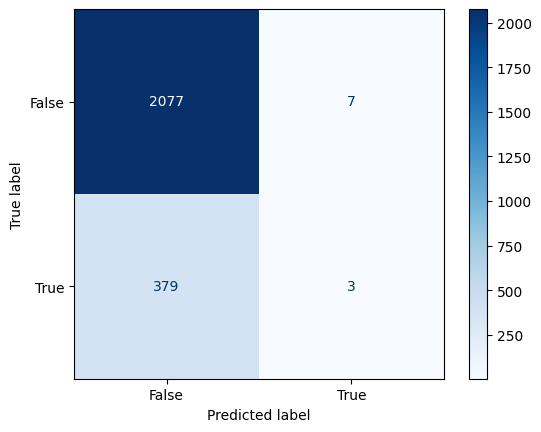

In [7]:
# YOUR CODE — Section 6: slice table / confusion reading / worst-miss inspection.
ConfusionMatrixDisplay.from_estimator(logreg, X_test, y_test["Revenue"], display_labels=[False, True], cmap=plt.cm.Blues)
plt.show()

In [8]:
print(X_test["VisitorType"].value_counts())
y_pred = logreg.predict(X_test)
returning = X_test["VisitorType"] == "Returning_Visitor"
f1_score(y_test["Revenue"][returning], y_pred[returning], average="macro", labels=[False, True], zero_division=0)

new_visitor = X_test["VisitorType"] == "New_Visitor"
f1_score(y_test["Revenue"][new_visitor], y_pred[new_visitor], average="macro", labels=[False, True], zero_division=0)

pd.DataFrame({
    "Returning Visitor Sessions": [returning.sum()],
    "New Visitor Sessions": [new_visitor.sum()],
    "Returning Visitor F1": [f1_score(y_test["Revenue"][returning],
    y_pred[returning], average="macro", labels=[False, True], zero_division=0)],   
    "New Visitor F1": [f1_score(y_test["Revenue"][new_visitor],
    y_pred[new_visitor], average="macro", labels=[False, True], zero_division=0)],
    "Overall F1": [f1_score(y_test["Revenue"], y_pred, average="macro", labels=[False, True], zero_division=0)]
})

VisitorType
Returning_Visitor    2108
New_Visitor           347
Other                  11
Name: count, dtype: int64


,Returning Visitor Sessions,New Visitor Sessions,Returning Visitor F1,New Visitor F1,Overall F1
0,2108,347,0.469512,0.423588,0.465142


## Section 7 of 7 — Limits — YOUR ANSWER

3–5 honest sentences. **TODO:**

- What this model cannot do yet:
- What it would need before anyone acted on it:
- What P3 (the deployment memo) will have to address:

### AI disclosure

**TODO:** Tool + what it did, or "I did not use AI."


## Before you submit

- [ ] File renamed to `CS6470_P2_LastName_FirstName.ipynb`
- [ ] Runs top to bottom on your data — no errors, no `NotImplementedError` left
- [ ] All 7 sections done, including the two written ones (1 and 7)
- [ ] Workplace data: only permitted, sanitized aggregate outputs are saved; private rows, identifiers, confidential values, paths, and raw files are not uploaded
- [ ] AI-use disclosure filled in

Upload the `.ipynb` to the **P2 — Working model** assignment on Canvas.

Integrity: the notebook must be yours. AI may help explain an error; it may not be the submitted analysis.
